# EDA 01 – surová data z TMDB

Průzkum vzorku stažených dat z Cloud Run Jobu `films-scraper` (`data/raw/tmdb/dt=…/run_…/`).

Cíl: zjistit, jak data vypadají, co je v nich vnořené, kde jsou prázdné nebo nulové hodnoty a co z toho chceme dostat do BigQuery.

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

RAW = Path("../data/raw/tmdb")
RUN = sorted(RAW.glob("dt=*/run_*"))[-1]   # nejnovější běh
print("run:", RUN)
for f in sorted(RUN.iterdir()):
    print(f"  {f.name:28} {f.stat().st_size / 1024:8.1f} kB")

run: ..\data\raw\tmdb\dt=2026-10-26\run_2026-10-26T11-45-16Z
  discover_page_001.json           12.8 kB
  manifest.json                     0.2 kB
  movie_details.jsonl            1374.9 kB
  upcoming_page_001.json           12.5 kB


## 1. Manifest běhu

In [2]:
json.loads((RUN / "manifest.json").read_text(encoding="utf-8"))

{'started_at': '2026-10-26T11:45:16.522992+00:00',
 'finished_at': '2026-10-26T11:45:20.232266+00:00',
 'language': 'en-US',
 'discover_pages': 1,
 'upcoming_pages': 1,
 'unique_movie_ids': 31,
 'details_ok': 31,
 'details_failed': []}

## 2. Seznamy filmů: `/discover/movie` a `/movie/upcoming`

Odpovědi jsou stránkované. Každá stránka obsahuje 20 filmů v `results` a metadata (`page`, `total_pages`, `total_results`).

In [3]:
discover = json.loads((RUN / "discover_page_001.json").read_text(encoding="utf-8"))
upcoming = json.loads((RUN / "upcoming_page_001.json").read_text(encoding="utf-8"))

for name, d in [("discover", discover), ("upcoming", upcoming)]:
    meta = {k: v for k, v in d.items() if k != "results"}
    print(f"{name:9} {meta}")

discover  {'page': 1, 'total_pages': 1001, 'total_results': 20001}
upcoming  {'dates': {'maximum': '2026-11-18', 'minimum': '2026-10-28'}, 'page': 1, 'total_pages': 88, 'total_results': 1745}


In [4]:
df_disc = pd.DataFrame(discover["results"]).assign(source="discover")
df_up = pd.DataFrame(upcoming["results"]).assign(source="upcoming")
df_list = pd.concat([df_disc, df_up], ignore_index=True)
print("sloupce:", list(df_disc.columns))
df_list.head(3)

sloupce: ['adult', 'backdrop_path', 'genre_ids', 'id', 'title', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'release_date', 'softcore', 'video', 'vote_average', 'vote_count', 'source']


,adult,backdrop_path,genre_ids,id,title,original_language,original_title,overview,popularity,poster_path,release_date,softcore,video,vote_average,vote_count,source
0,False,/r08LxMJCbf1SiJIWeyH9aJmdqwC.jpg,"[878, 28, 12]",969681,Spider-Man: Brand New Day,en,Spider-Man: Brand New Day,Fighting crime full-time as Spider-Man in a world that doesn't remember him—...,868.7427,/bjiS5ipwxb9JFy3XRRN4OAilSeX.jpg,2026-07-29,False,False,8.474,6168,discover
1,False,/8Tfys3mDZVp4tNoH2ktm06a0Tau.jpg,"[878, 12]",687163,Project Hail Mary,en,Project Hail Mary,Science teacher Ryland Grace wakes up on a spaceship light years from home w...,559.3291,/iOb2fjXLbpJgyQXe46n1WtGCnaa.jpg,2026-03-15,False,False,8.634,8534,discover
2,False,/g3gpP5YDbA85DsA0bt5mgGQIe5q.jpg,"[878, 28, 12]",1003596,Avengers: Doomsday,en,Avengers: Doomsday,Beloved heroes from three distinct universes are set on a deadly collision c...,417.6091,/sLYCyO58UvBuBtbHTQjPCCgJ4dG.jpg,2026-12-16,False,False,0.000,0,discover


In [5]:
both = set(df_disc["id"]) & set(df_up["id"])
print(f"discover: {len(df_disc)}, upcoming: {len(df_up)}, v obou: {len(both)}, unikátních: {df_list['id'].nunique()}")

# Je upcoming opravdu "budoucí"? Porovnání release_date se dnem běhu a s oknem 'dates' z odpovědi
run_date = RUN.parent.name.removeprefix("dt=")
print("den běhu:", run_date, "| okno upcoming.dates:", upcoming["dates"])
lo, hi = upcoming["dates"]["minimum"], upcoming["dates"]["maximum"]
print("upcoming release_date:", df_up["release_date"].min(), "→", df_up["release_date"].max())
print("v okně dates:", df_up["release_date"].between(lo, hi).sum(), "/", len(df_up),
      "| po dni běhu:", (df_up["release_date"] > run_date).sum(), "/", len(df_up))

discover: 20, upcoming: 20, v obou: 9, unikátních: 31
den běhu: 2026-10-26 | okno upcoming.dates: {'maximum': '2026-11-18', 'minimum': '2026-10-28'}
upcoming release_date: 2026-04-09 → 2026-10-29
v okně dates: 2 / 20 | po dni běhu: 2 / 20


## 3. Detail filmu (`/movie/{id}?append_to_response=credits,keywords`)

Hlavní datový zdroj. Jeden řádek JSONL odpovídá jednomu filmu.

In [6]:
details = [json.loads(line) for line in (RUN / "movie_details.jsonl").read_text(encoding="utf-8").splitlines()]
print("filmů:", len(details))

# Typ a ukázka každého top-level pole
rows = []
for k, v in details[0].items():
    size = len(v) if isinstance(v, (list, dict)) else None
    rows.append({"pole": k, "typ": type(v).__name__, "délka": size, "ukázka": str(v)[:70]})
pd.DataFrame(rows)

filmů: 31


,pole,typ,délka,ukázka
0,adult,bool,NaN,False
1,backdrop_path,str,NaN,/r08LxMJCbf1SiJIWeyH9aJmdqwC.jpg
2,belongs_to_collection,dict,4.0,"{'id': 531241, 'name': 'Spider-Man (MCU) Collection', 'poster_path': '"
3,budget,int,NaN,225000000
4,genres,list,3.0,"[{'id': 878, 'name': 'Science Fiction'}, {'id': 28, 'name': 'Action'},"
5,homepage,str,NaN,https://spidermanbrandnewday.movie
6,id,int,NaN,969681
7,imdb_id,str,NaN,tt22084616
8,origin_country,list,1.0,['US']
9,original_language,str,NaN,en


### 3.1 Ploché sloupce: chybějící, prázdné a nulové hodnoty

In [7]:
nested = ["credits", "keywords", "genres", "production_companies", "production_countries",
          "spoken_languages", "belongs_to_collection", "origin_country"]
df = pd.DataFrame([{k: v for k, v in d.items() if k not in nested} for d in details])

def emptiness(s):
    return pd.Series({
        "null": s.isna().sum(),
        "prázdný_string": (s.astype(str).str.strip() == "").sum(),
        "nula": (s == 0).sum() if pd.api.types.is_numeric_dtype(s) and s.dtype != bool else 0,
        "unikátních": s.nunique(),
        "dtype": str(s.dtype),
    })

df.apply(emptiness).T.sort_values(["null", "prázdný_string", "nula"], ascending=False)

,null,prázdný_string,nula,unikátních,dtype
tagline,0,6,0,26,str
homepage,0,3,0,29,str
budget,0,0,9,19,int64
revenue,0,0,9,23,int64
vote_average,0,0,1,31,float64
vote_count,0,0,1,30,int64
adult,0,0,0,1,bool
backdrop_path,0,0,0,31,str
id,0,0,0,31,int64
imdb_id,0,0,0,31,str


In [8]:
df.head(5)

,adult,backdrop_path,budget,homepage,id,imdb_id,original_language,original_title,overview,popularity,poster_path,release_date,revenue,runtime,softcore,status,tagline,title,video,vote_average,vote_count
0,False,/r08LxMJCbf1SiJIWeyH9aJmdqwC.jpg,225000000,https://spidermanbrandnewday.movie,969681,tt22084616,en,Spider-Man: Brand New Day,Fighting crime full-time as Spider-Man in a world that doesn't remember him—...,868.7427,/bjiS5ipwxb9JFy3XRRN4OAilSeX.jpg,2026-07-29,2517281128,145,False,Released,A brand new day starts now.,Spider-Man: Brand New Day,False,8.474,6163
1,False,/8Tfys3mDZVp4tNoH2ktm06a0Tau.jpg,200000000,https://www.amazon.com/salp/projecthailmary?hhf,687163,tt12042730,en,Project Hail Mary,Science teacher Ryland Grace wakes up on a spaceship light years from home w...,559.3291,/iOb2fjXLbpJgyQXe46n1WtGCnaa.jpg,2026-03-15,684586806,157,False,Released,Believe in the Hail Mary.,Project Hail Mary,False,8.633,8533
2,False,/g3gpP5YDbA85DsA0bt5mgGQIe5q.jpg,0,https://www.marvel.com/movies/avengers-doomsday,1003596,tt21357150,en,Avengers: Doomsday,Beloved heroes from three distinct universes are set on a deadly collision c...,417.6091,/sLYCyO58UvBuBtbHTQjPCCgJ4dG.jpg,2026-12-16,0,165,False,Post Production,,Avengers: Doomsday,False,0.000,0
3,False,/qqHFLg90IUSoTmSMpKOOW5RyqN3.jpg,46000000,https://www.neonrated.com/film/hope,1058424,tt27369017,ko,호프,"In the remote South Korean village of Hope Harbor, police chief Bum-seok and...",587.0228,/6VY1ZKgpsc8CfGsQcCGiYEgHdH0.jpg,2026-07-15,41212538,157,False,Released,Is this how it ends?,Hope,False,6.784,341
4,False,/bulFtfy3oBQtCnAMSi7g6DSSds3.jpg,250000000,https://www.universalpictures.com/movies/the-odyssey,1368337,tt33764258,en,The Odyssey,"Odysseus, the legendary King of Ithaca, embarks on a long and perilous journ...",348.8879,/krVa7rKCQb4OBfsr2LTJv4rTz5q.jpg,2026-07-15,1794403000,173,False,Released,Defy the gods.,The Odyssey,False,8.015,4267


### 3.2 Numerické sloupce

In [9]:
num = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]
df[num].describe().T

,count,mean,std,min,25%,50%,75%,max
budget,31.0,4.613710e+07,6.762155e+07,0.0000,0.00000,1.800000e+07,7.350000e+07,2.500000e+08
revenue,31.0,2.217255e+08,5.482261e+08,0.0000,0.00000,3.127343e+07,1.025149e+08,2.517281e+09
runtime,31.0,1.184516e+02,2.602158e+01,82.0000,98.50000,1.090000e+02,1.320000e+02,1.740000e+02
popularity,31.0,2.212085e+02,1.746458e+02,78.5783,126.42145,1.544923e+02,2.155239e+02,8.687427e+02
vote_average,31.0,7.108871e+00,1.635304e+00,0.0000,6.69250,7.288000e+00,8.092500e+00,9.100000e+00
vote_count,31.0,1.112806e+03,2.141360e+03,0.0000,81.00000,1.930000e+02,7.605000e+02,8.533000e+03


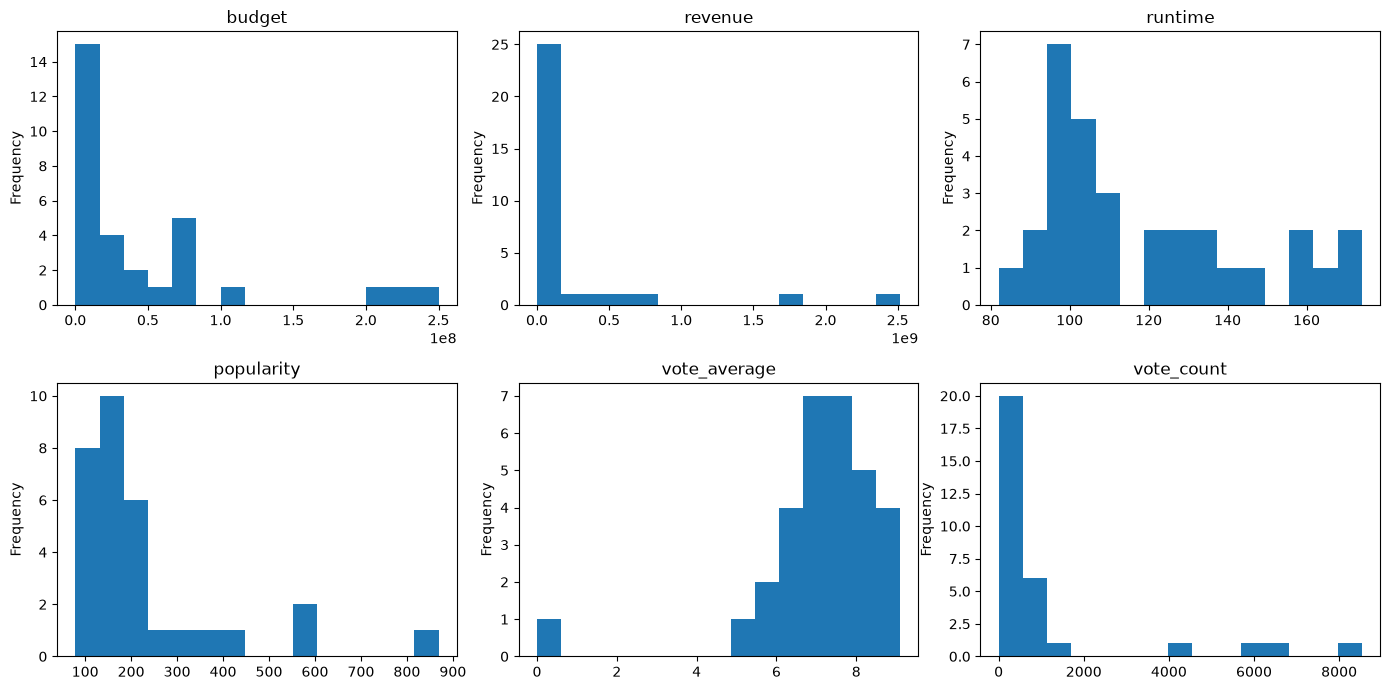

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, num):
    df[col].plot.hist(ax=ax, bins=15, title=col)
plt.tight_layout()

In [11]:
# Filmy s budget/revenue = 0: TMDB nezná hodnotu (není to skutečná nula)
df.loc[(df["budget"] == 0) | (df["revenue"] == 0), ["id", "title", "release_date", "status", "budget", "revenue", "vote_count"]]

,id,title,release_date,status,budget,revenue,vote_count
2,1003596,Avengers: Doomsday,2026-12-16,Post Production,0,0,0
9,1148365,Matchbox the Movie,2026-10-05,Released,0,0,512
10,1561726,Masterplan,2026-10-16,Released,0,0,170
12,1228834,The Fix,2026-09-10,Released,32000000,0,77
16,1236045,Animals,2026-10-09,Released,0,0,601
19,1712451,Resident Dead,2026-09-04,Released,0,0,52
22,1294189,The Mongoose,2026-10-29,Released,0,0,4
23,1377237,Runner,2026-09-07,Released,0,18029340,727
26,1284186,Sacrifice,2026-04-09,Released,0,0,85
28,1657630,The Awakening,2026-10-29,Released,0,0,4


### 3.3 Kategorie a data

In [12]:
for col in ["status", "original_language", "adult", "video", "softcore"]:
    print(col, dict(Counter(df[col])))

df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
print()
print("release_date:", df["release_date"].min().date(), "→", df["release_date"].max().date())
print("filmy s release_date v budoucnu vůči dni běhu:", (df["release_date"] > run_date).sum())

status {'Released': 30, 'Post Production': 1}
original_language {'en': 28, 'ko': 2, 'es': 1}
adult {False: 31}
video {False: 31}
softcore {False: 31}

release_date: 2026-03-15 → 2026-12-16
filmy s release_date v budoucnu vůči dni běhu: 3


## 4. Vnořená pole

Seznamy objektů `{id, name, …}` nebo slovníky. V BigQuery z nich budou `ARRAY<STRING>` / `ARRAY<STRUCT>`.

In [13]:
for col in ["genres", "production_companies", "production_countries", "spoken_languages", "origin_country"]:
    lens = [len(d[col]) for d in details]
    print(f"{col:22} prázdných: {sum(l == 0 for l in lens):2}  max položek: {max(lens):2}  ukázka: {details[0][col][:2]}")

print()
print("belongs_to_collection (null):", sum(d["belongs_to_collection"] is None for d in details), "| ukázka:", details[0]["belongs_to_collection"])

genres                 prázdných:  0  max položek:  5  ukázka: [{'id': 878, 'name': 'Science Fiction'}, {'id': 28, 'name': 'Action'}]
production_companies   prázdných:  0  max položek:  9  ukázka: [{'id': 420, 'logo_path': '/hUzeosd33nzE5MCNsZxCGEKTXaQ.png', 'name': 'Marvel Studios', 'origin_country': 'US'}, {'id': 5, 'logo_path': '/71BqEFAF4V3qjjMPCpLuyJFB9A.png', 'name': 'Columbia Pictures', 'origin_country': 'US'}]
production_countries   prázdných:  0  max položek:  4  ukázka: [{'iso_3166_1': 'US', 'name': 'United States of America'}]
spoken_languages       prázdných:  2  max položek:  5  ukázka: [{'english_name': 'English', 'iso_639_1': 'en', 'name': 'English'}]
origin_country         prázdných:  0  max položek:  2  ukázka: ['US']

belongs_to_collection (null): 25 | ukázka: {'id': 531241, 'name': 'Spider-Man (MCU) Collection', 'poster_path': '/yeba3Y820OjApZO9aJevDsNeMEd.jpg', 'backdrop_path': '/AvnqpRwlEaYNVL6wzC4RN94EdSd.jpg'}


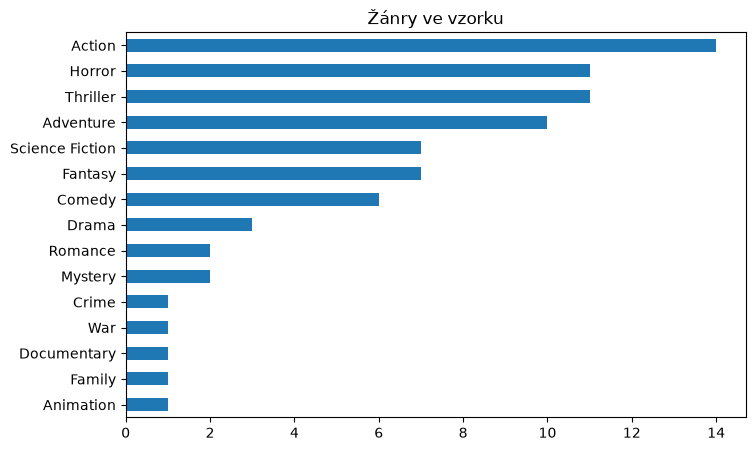

In [14]:
genres = Counter(g["name"] for d in details for g in d["genres"])
pd.Series(genres).sort_values().plot.barh(figsize=(8, 5), title="Žánry ve vzorku");

## 5. Credits: obsazení (`cast`) a štáb (`crew`)

Největší část dat. Starý projekt ukládal štáb jako `{job: name}`, takže ztrácel lidi se stejnou rolí.

In [15]:
print("cast položka:", list(details[0]["credits"]["cast"][0].keys()))
print("crew položka:", list(details[0]["credits"]["crew"][0].keys()))

sizes = pd.DataFrame({
    "title": [d["title"] for d in details],
    "cast": [len(d["credits"]["cast"]) for d in details],
    "crew": [len(d["credits"]["crew"]) for d in details],
})
sizes.describe().T

cast položka: ['adult', 'gender', 'id', 'known_for_department', 'name', 'original_name', 'popularity', 'profile_path', 'cast_id', 'character', 'credit_id', 'order']
crew položka: ['adult', 'gender', 'id', 'known_for_department', 'name', 'original_name', 'popularity', 'profile_path', 'credit_id', 'department', 'job']


,count,mean,std,min,25%,50%,75%,max
cast,31.0,34.387097,18.920320,5.0,21.0,34.0,47.5,75.0
crew,31.0,114.580645,116.946647,13.0,29.5,78.0,171.5,540.0


In [16]:
pd.DataFrame(details[0]["credits"]["cast"]).sort_values("order")[["order", "name", "character", "known_for_department", "popularity"]].head(10)

,order,name,character,known_for_department,popularity
0,0,Tom Holland,Peter Parker / Spider-Man,Acting,14.4799
1,1,Sadie Sink,Jean Grey,Acting,12.0284
2,2,Tramell Tillman,William 'Bill' Metzger,Acting,2.0111
3,3,Zendaya,MJ,Acting,10.1786
4,4,Jacob Batalon,Ned Leeds,Acting,3.5651
5,5,Jon Bernthal,Frank Castle / Punisher,Acting,8.2661
6,6,Mark Ruffalo,Bruce Banner / Hulk,Acting,5.8800
7,7,Florence Pugh,Yelena Belova / Black Widow,Acting,11.4455
8,8,Liza Colón-Zayas,Detective Jean DeWolff,Acting,1.5326
9,9,Marisa Tomei,May Parker,Acting,5.1286


In [17]:
crew = pd.DataFrame([{**c, "movie_id": d["id"]} for d in details for c in d["credits"]["crew"]])
print("řádků crew:", len(crew), "| unikátních jobů:", crew["job"].nunique(), "| departmentů:", crew["department"].nunique())
crew["job"].value_counts().head(20)

řádků crew: 3552 | unikátních jobů: 384 | departmentů: 11


job
Stunts                        293
Executive Producer            152
Producer                      128
Visual Effects Supervisor      80
Thanks                         67
Visual Effects Producer        61
Art Direction                  50
Stunt Double                   42
Editor                         38
Compositing Supervisor         36
Special Effects Technician     36
Director                       35
Casting                        35
Visual Effects Coordinator     35
Makeup Artist                  35
Digital Compositor             35
Sound Effects Editor           34
Writer                         32
Original Music Composer        32
Director of Photography        31
Name: count, dtype: int64

In [18]:
# Kolik lidí má film v klíčových rolích (víc než 1 = starý {job: name} přístup by je ztratil)
key_jobs = ["Director", "Producer", "Screenplay", "Writer", "Director of Photography", "Original Music Composer", "Editor"]
per_movie = crew[crew["job"].isin(key_jobs)].groupby(["movie_id", "job"]).size().unstack(fill_value=0)
per_movie.describe().T[["mean", "min", "max"]]

,mean,min,max
job,,,
Director,1.129032,1.0,2.0
Director of Photography,1.000000,0.0,2.0
Editor,1.225806,0.0,3.0
Original Music Composer,1.032258,0.0,2.0
Producer,4.129032,1.0,12.0
Screenplay,0.548387,0.0,3.0
Writer,1.032258,0.0,4.0


## 6. Keywords

In [19]:
kw_lens = [len(d["keywords"]["keywords"]) for d in details]
print("keywords na film: min", min(kw_lens), "max", max(kw_lens), "| bez keywords:", sum(l == 0 for l in kw_lens))
Counter(k["name"] for d in details for k in d["keywords"]["keywords"]).most_common(15)

keywords na film: min 3 max 19 | bez keywords: 0


[('based on novel or book', 6),
 ('sequel', 5),
 ('supernatural', 5),
 ('supernatural horror', 4),
 ('based on comic', 3),
 ('cautionary', 3),
 ('dramatic', 3),
 ('aggressive', 3),
 ('independent film', 3),
 ('zombie', 3),
 ('new york city', 2),
 ('superhero', 2),
 ('aftercreditsstinger', 2),
 ('marvel cinematic universe (mcu)', 2),
 ('friendship', 2)]

## 7. Velikost dat: co zabírá místo

Kvůli odhadu objemu při plném scrapingu a rozhodnutí, co ukládat do BigQuery.

In [20]:
size = pd.DataFrame([{k: len(json.dumps(v, ensure_ascii=False)) for k, v in d.items()} for d in details])
share = (size.sum() / size.sum().sum() * 100).sort_values(ascending=False)
print(f"průměr na film: {size.sum(axis=1).mean() / 1024:.1f} kB")
share.head(8).round(1)

průměr na film: 43.8 kB


credits                 96.3
keywords                 1.0
production_companies     1.0
overview                 0.6
spoken_languages         0.2
genres                   0.2
production_countries     0.2
homepage                 0.1
dtype: float64

In [21]:
# Uvnitř credits: cast vs crew
cc = pd.Series({
    "cast": sum(len(json.dumps(d["credits"]["cast"], ensure_ascii=False)) for d in details),
    "crew": sum(len(json.dumps(d["credits"]["crew"], ensure_ascii=False)) for d in details),
})
(cc / cc.sum() * 100).round(1)

cast    24.1
crew    75.9
dtype: float64

## 8. Závěry pro cleaning

Platí pro vzorek 31 filmů z běhu 2026-10-26. Při plném scrapingu je potřeba je ověřit znovu.

**Zdroje filmů**
- `/movie/upcoming` bez parametru `region` vrací hlavně **už vydané** filmy. Jen 2 z 20 mají `release_date` po dni běhu nebo v okně `dates`. Pro skutečně budoucí filmy je potřeba použít `region` nebo `/discover/movie` s filtrem `primary_release_date.gte`.
- `/discover/movie` hlásí `total_pages = 1001`, ale TMDB vrací nejvýš 500 stránek. Plný katalog je tedy potřeba stahovat po řezech, například po letech.
- Detail filmu (`/movie/{id}`) obsahuje všechno ze seznamů a ještě víc, takže pro BigQuery stačí jako jediný zdroj. Seznamy slouží jen k výběru ID.

**Hodnoty, které znamenají „neznámé“ (→ `NULL`)**
- `budget = 0` a `revenue = 0` (9 z 31 filmů): TMDB hodnotu nezná, nejde o skutečnou nulu.
- `vote_average = 0` při `vote_count = 0`: film ještě nemá hlasy (například `Post Production`).
- Prázdné stringy: `tagline` (6×) a `homepage` (3×).
- `belongs_to_collection` je `null` u 25 z 31 filmů, je to normální stav.

**Typy**
- `release_date`: string → `DATE`.
- `vote_average` a `popularity` zůstanou jako `FLOAT64` (starý projekt je chybně přetypovával na `int`).
- `budget` a `revenue`: `INT64` (hodnoty přes 2,5 mld. se do 32bitového intu nevejdou).

**Sloupce k vynechání**
- `adult`, `video` a `softcore` jsou vždy `False` (adult filtrujeme už při stahování).
- `backdrop_path` a `poster_path` jsou jen relativní cesty k obrázkům. `poster_path` můžeme nechat kvůli zobrazení plakátu v aplikaci.

**Vnořená pole → `ARRAY` v BigQuery**
- `genres`, `production_companies`, `production_countries`, `spoken_languages`, `origin_country` a `keywords` (3 až 19 na film) uložit jako `ARRAY<STRING>` jmen. `keywords` budou užitečné pro hledání v aplikaci.
- `belongs_to_collection` stačí jako `collection_name`.

**Credits: 96 % objemu dat (průměr 44 kB na film, z toho 76 % crew)**
- Crew má 384 různých jobů. Užitečné jsou jen klíčové role: `Director`, `Writer`/`Screenplay`, `Producer`, `Director of Photography`, `Original Music Composer` a `Editor`.
- Role mívají víc lidí (až 2 režiséři, až 12 producentů), proto je potřeba `ARRAY<STRING>` na roli, ne `{job: name}`.
- Cast stačí prvních N herců podle `order` (například 10) jako `ARRAY<STRUCT<name, character, order>>`.
- Surová data zůstávají kompletní v GCS, takže se k dalším rolím dá kdykoli vrátit.